# Week 4: Conway's Game of Life and Emergent Objects

**Project:** Emergent Complexity in Cellular Automata
**Notebook:** `04_game_of_life.ipynb`
**Estimated time:** 8 to 10 hours

In the first three weeks you studied local rules, classification and perturbation spreading in one-dimensional cellular automata. This week we add a second spatial dimension.

Our main research question:

> **How can cells that stay at fixed positions and only switch between alive and dead form persistent objects that move like particles?**

This question is central to the overall theme of the project. A new description that is not explicitly present in the microscopic rules can **emerge** at a larger scale.

## From the previous weeks to this week

- **Week 1:** You saw that a local rule turns an initial condition into a large-scale pattern.
- **Week 2:** You supported visual patterns with observables such as density and activity, and you learned that a single number does not fully explain spatial structure.
- **Week 3:** You measured that one-cell information can disappear, stay local or spread within a light cone.
- **Week 4:** We now study the spatial structures themselves: still objects, oscillators and moving gliders.

Two dimensions make it possible for a pattern not only to grow but also to **move** while keeping its shape. This is also the basis for Week 5, in which we study random initial conditions and ensemble statistics.

### Learning objectives

By the end of this notebook you should be able to:

1. count eight neighbours with periodic boundaries
2. implement the B3/S23 rule of the Game of Life
3. simulate a two-dimensional cellular automaton
4. reproduce examples of still lifes, oscillators and gliders
5. measure population and period
6. compute the displacement and effective velocity of a glider
7. explain why the glider is an emergent object.

## Model: B3/S23

Let the state of each cell be

$$
s_{ij}(t)\in\{0,1\}.
$$

Cell $(i,j)$ interacts with the eight cells around it. The centre cell itself is not counted as a neighbour.

At the next step:

- **Birth (B3):** A dead cell becomes alive if it has exactly 3 live neighbours.
- **Survival (S23):** A live cell stays alive if it has 2 or 3 live neighbours.
- In all other cases the cell dies or stays dead.

This rule is written compactly as **B3/S23**.

### Predict before running

1. What happens to an isolated live cell?
2. What happens to the cells in the interior of a large completely filled region?
3. Can a pattern move without physically transporting cells?

**My predictions:**

> An isolated live cell has no live neighbours. It therefore dies of isolation after one step. A cell in the interior of a large filled region has eight live neighbours, which means overcrowding, so that cell also dies. A pattern can move without physically transporting cells, because some cells die while cells at other positions are born. In this way the same large-scale shape reappears at another position a few steps later. What moves is not the individual cells but the pattern itself.

<details>
<summary>Hint: Count the neighbours in the first two questions</summary>

An isolated cell has no live neighbours and dies of isolation. An interior cell of a completely filled region has eight live neighbours and dies of overcrowding.
</details>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 120
plt.rcParams["image.cmap"] = "binary"


def check(label, test_function):
    '''Run a student test without stopping the notebook.'''
    try:
        test_function()
    except (AssertionError, NotImplementedError) as error:
        message = str(error) or "result did not match the expected value"
        print(f"○ {label}: keep working: {message}")
    else:
        print(f"✓ {label}: passed")


print("Setup complete.")

Setup complete.


## 1. Counting eight neighbours

We can shift a two-dimensional array up, down, right and left with `np.roll`. The sum of the eight different shifts along the two axes gives the number of neighbours.

We use periodic boundaries. The neighbour of the top edge is on the bottom edge and the neighbour of the left edge is on the right edge. Mathematically this turns the grid into the surface of a torus.

### Exercise 1

Complete the function `count_neighbors`. Loop `di` and `dj` over `(-1, 0, 1)`. Do not add the `(0, 0)` shift, because that is the centre cell itself.

In [2]:
def count_neighbors(grid):
    '''Count the live cells among the eight neighbours of every cell with periodic boundaries.'''
    grid = np.asarray(grid, dtype=np.uint8)
    neighbors = np.zeros_like(grid, dtype=np.uint8)

    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(grid, di, axis=0), dj, axis=1)

    return neighbors

In [3]:
def test_count_neighbors():
    grid = np.zeros((5, 5), dtype=np.uint8)
    grid[2, 2] = 1
    result = count_neighbors(grid)
    expected = np.zeros((5, 5), dtype=np.uint8)
    expected[1:4, 1:4] = 1
    expected[2, 2] = 0
    assert np.array_equal(result, expected), "the neighbours of the single centre cell are wrong"

    corner = np.zeros((4, 4), dtype=np.uint8)
    corner[0, 0] = 1
    wrapped = count_neighbors(corner)
    assert wrapped[3, 3] == 1 and wrapped[0, 3] == 1 and wrapped[3, 0] == 1, (
        "the periodic boundary must wrap around the corners"
    )
    assert wrapped.sum() == 8, "a single live cell must neighbour exactly eight cells"


check("Exercise 1: neighbour count", test_count_neighbors)

✓ Exercise 1: neighbour count: passed


### Reference neighbour count

So that the large experiments run before the TODO is completed, the reference function below is used. Once your test passes, compare it with your own function to check that they give the same result.

In [4]:
def _count_neighbors_reference(grid):
    grid = np.asarray(grid, dtype=np.uint8)
    neighbors = np.zeros_like(grid, dtype=np.uint8)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(grid, di, axis=0), dj, axis=1)
    return neighbors

## 2. Implementing the B3/S23 update

First compute the number of neighbours. Then build two Boolean masks:

```python
birth = (grid == 0) & (neighbors == 3)
survival = (grid == 1) & ((neighbors == 2) | (neighbors == 3))
```

The new state is the expression `birth | survival` converted to a 0/1 array.

### Exercise 2

Complete the function `update_life`. In this exercise use your own `count_neighbors` function.

In [5]:
def update_life(grid):
    '''Advance a Game of Life grid by one time step.'''
    grid = np.asarray(grid, dtype=np.uint8)
    neighbors = count_neighbors(grid)
    birth = (grid == 0) & (neighbors == 3)
    survival = (grid == 1) & ((neighbors == 2) | (neighbors == 3))
    return (birth | survival).astype(np.uint8)

In [6]:
def test_update_life():
    isolated = np.zeros((7, 7), dtype=np.uint8)
    isolated[3, 3] = 1
    assert update_life(isolated).sum() == 0, "an isolated cell must die in one step"

    block = np.zeros((7, 7), dtype=np.uint8)
    block[2:4, 2:4] = 1
    assert np.array_equal(update_life(block), block), "a 2×2 block must stay fixed"

    birth_case = np.zeros((7, 7), dtype=np.uint8)
    birth_case[2, 3] = birth_case[3, 2] = birth_case[3, 4] = 1
    assert update_life(birth_case)[3, 3] == 1, "a centre cell with three neighbours must be born"


check("Exercise 2: B3/S23 update", test_update_life)

✓ Exercise 2: B3/S23 update: passed


### Reference update function

In [7]:
def _update_life_reference(grid):
    grid = np.asarray(grid, dtype=np.uint8)
    neighbors = _count_neighbors_reference(grid)
    birth = (grid == 0) & (neighbors == 3)
    survival = (grid == 1) & ((neighbors == 2) | (neighbors == 3))
    return (birth | survival).astype(np.uint8)

## 3. Multi-step simulation

A Game of Life history has the shape

```text
(time, row, column)
```

The first layer is the initial grid.

### Exercise 3

Complete the function `simulate_life`. Compute each new grid from the previous grid.

In [8]:
def simulate_life(initial_grid, steps):
    '''Return the Game of Life history including the initial state.'''
    initial_grid = np.asarray(initial_grid, dtype=np.uint8)
    history = np.zeros((steps, *initial_grid.shape), dtype=np.uint8)
    history[0] = initial_grid
    for t in range(1, steps):
        history[t] = update_life(history[t - 1])
    return history

In [9]:
def test_simulate_life():
    block = np.zeros((7, 7), dtype=np.uint8)
    block[2:4, 2:4] = 1
    history = simulate_life(block, 5)
    assert history.shape == (5, 7, 7), f"expected shape (5, 7, 7), found {history.shape}"
    assert np.all(history == block), "the block must stay the same at all times"

    isolated = np.zeros((7, 7), dtype=np.uint8)
    isolated[3, 3] = 1
    isolated_history = simulate_life(isolated, 3)
    assert isolated_history[0].sum() == 1 and isolated_history[1:].sum() == 0, (
        "the isolated cell must die out after the start"
    )


check("Exercise 3: multi-step simulation", test_simulate_life)

✓ Exercise 3: multi-step simulation: passed


### Reference simulation function

In [10]:
def _simulate_life_reference(initial_grid, steps):
    initial_grid = np.asarray(initial_grid, dtype=np.uint8)
    history = np.zeros((steps, *initial_grid.shape), dtype=np.uint8)
    history[0] = initial_grid
    for t in range(1, steps):
        history[t] = _update_life_reference(history[t - 1])
    return history

## 4. Preparing known structures

The helper function below places a small pattern, given as a list of coordinates, on a large grid. Coordinates are in `(row, column)` form.

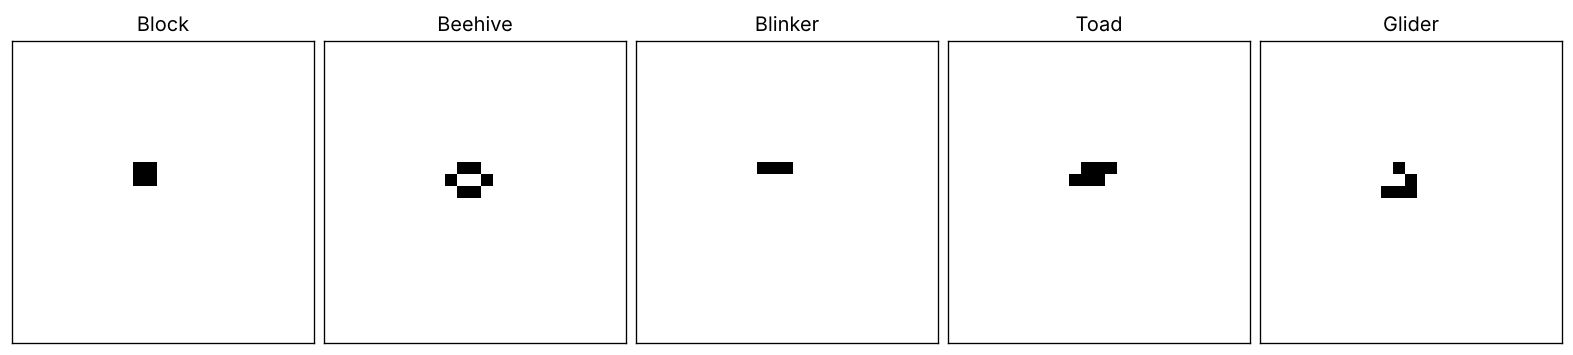

In [11]:
def place_pattern(shape, coordinates, top_left=(0, 0)):
    '''Place a list of coordinates on the grid starting from the given top-left position.'''
    grid = np.zeros(shape, dtype=np.uint8)
    row0, col0 = top_left
    for row, col in coordinates:
        grid[row0 + row, col0 + col] = 1
    return grid


PATTERNS = {
    "Block": [(0, 0), (0, 1), (1, 0), (1, 1)],
    "Beehive": [(0, 1), (0, 2), (1, 0), (1, 3), (2, 1), (2, 2)],
    "Blinker": [(0, 0), (0, 1), (0, 2)],
    "Toad": [(0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2)],
    "Glider": [(0, 1), (1, 2), (2, 0), (2, 1), (2, 2)],
}

initial_patterns = {
    name: place_pattern((25, 25), coordinates, top_left=(10, 10))
    for name, coordinates in PATTERNS.items()
}

fig, axes = plt.subplots(1, 5, figsize=(13, 3), constrained_layout=True)
for ax, (name, grid) in zip(axes, initial_patterns.items()):
    ax.imshow(grid, interpolation="nearest", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

### Classify the structures before running

| Structure | My prediction: still, periodic or moving | Reason for my prediction |
|---|---|---|
| Block | Still | Every cell has exactly two live neighbours. No cell is born and no cell dies |
| Beehive | Still | The neighbour counts of the outer cells do not trigger the birth or death conditions, so the pattern stays the same |
| Blinker | Periodic | The three cells switch from a horizontal to a vertical position and back to horizontal |
| Toad | Periodic | The pattern oscillates between two different shapes but stays in place |
| Glider | Moving | The shape stays the same while its position shifts diagonally after a few steps |

<details>
<summary>Question: Are the cells in a still structure never updated?</summary>

The cells perform the same B3/S23 calculation at every step. However, the birth and death conditions make the whole pattern come out identical to the previous step. Being "still" does not mean that the update stops. It means that the result of the update does not change.
</details>

## 5. Still lifes, oscillators and moving structures

For each structure we show the first five times side by side. Because the reference engine is used, this figure runs even before the TODO cells are completed.

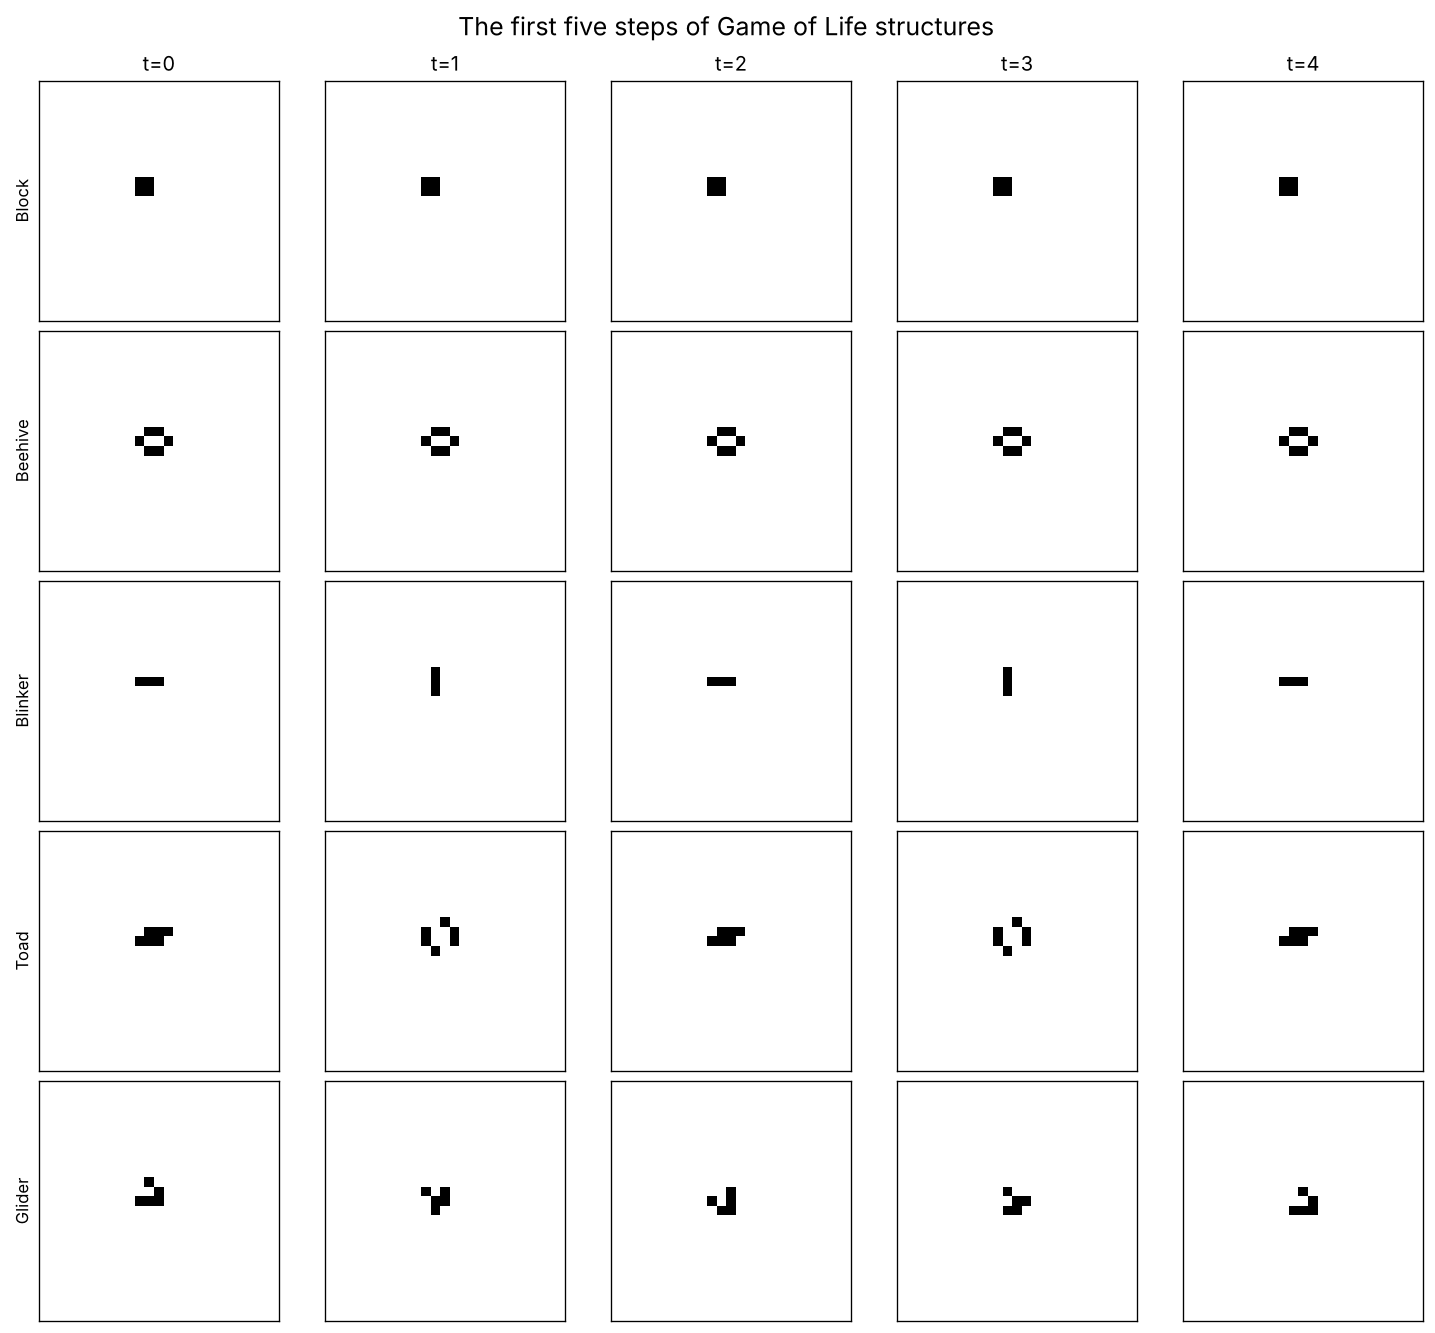

In [12]:
pattern_histories = {
    name: _simulate_life_reference(grid, 12)
    for name, grid in initial_patterns.items()
}

frames = [0, 1, 2, 3, 4]
fig, axes = plt.subplots(len(PATTERNS), len(frames), figsize=(12, 11), constrained_layout=True)

for row, (name, history) in enumerate(pattern_histories.items()):
    for col, t in enumerate(frames):
        ax = axes[row, col]
        ax.imshow(history[t], interpolation="nearest", vmin=0, vmax=1)
        if row == 0:
            ax.set_title(f"t={t}")
        if col == 0:
            ax.set_ylabel(name)
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle("The first five steps of Game of Life structures", fontsize=15)
plt.show()

### Observations

Fill in the table using the figure:

| Structure | Population | Period | Displacement per period | Type |
|---|---:|---:|---|---|
| Block | 4 | 1 | none | still life |
| Beehive | 6 | 1 | none | still life |
| Blinker | 3 | 2 | none | oscillator |
| Toad | 6 | 2 | none | oscillator |
| Glider | 5 | 4 | 1 cell diagonally | spaceship |

*[Correction made during review: the original table gave the toad population as "between 6 and 8". The population time series computed in Section 6 of this notebook shows that the toad has exactly 6 live cells in both phases. The value has been corrected to 6.]*

In the "Type" column use one of the terms **still life**, **oscillator** or **spaceship**.

<details>
<summary>Terminology</summary>

- **Still life:** A pattern that stays exactly the same after an update.
- **Oscillator:** A pattern that repeats at the same position and orientation after a fixed number of steps.
- **Spaceship:** A pattern that regains its shape and orientation after a fixed number of steps while moving to another position.
</details>

## 6. Population time series

The number of live cells

$$
N_{\mathrm{alive}}(t)=\sum_{i,j}s_{ij}(t)
$$

shows whether a structure grows or shrinks. However, a constant population does not imply a constant pattern.

### Exercise 4

Complete the function `population_time_series`. Sum over the spatial axes `axis=(1, 2)`.

In [13]:
def population_time_series(history):
    '''Return the number of live cells at each time.'''
    history = np.asarray(history)
    return history.sum(axis=(1, 2))

In [14]:
def test_population_time_series():
    history = np.array([
        [[0, 0], [0, 0]],
        [[1, 0], [0, 0]],
        [[1, 1], [1, 0]],
    ])
    result = population_time_series(history)
    expected = np.array([0, 1, 3])
    assert np.array_equal(result, expected), f"expected {expected}, found {result}"


check("Exercise 4: population", test_population_time_series)

✓ Exercise 4: population: passed


### Reference population measurement and figure

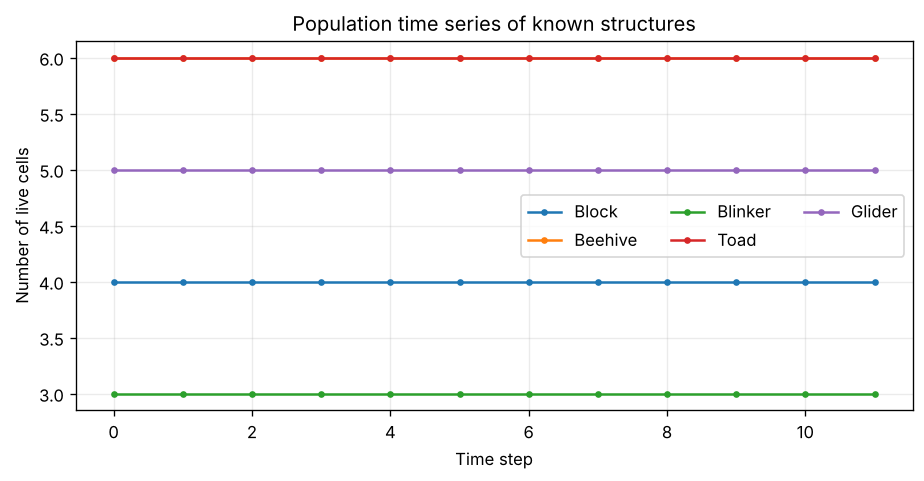

In [15]:
def _population_reference(history):
    return np.asarray(history).sum(axis=(1, 2))


fig, ax = plt.subplots(figsize=(9, 4))
for name, history in pattern_histories.items():
    ax.plot(_population_reference(history), marker="o", markersize=3, label=name)

ax.set(
    xlabel="Time step",
    ylabel="Number of live cells",
    title="Population time series of known structures",
)
ax.grid(alpha=0.25)
ax.legend(ncol=3)
plt.show()

<details>
<summary>Question: If the blinker and the block had the same population, could the population plot distinguish them?</summary>

No. The population only knows the total number of live cells, not their positions. An oscillator with constant population can change shape at every step while its population plot is a flat line.
</details>

## 7. Period detection

If the last state of a history equals the state $p$ steps earlier, then $p$ is a possible period. We search for the smallest positive $p$.

This simple method does not analyse transient behaviour in full. It only looks for a repetition at the end of the history.

### Exercise 5

Complete the function `detect_period`. Try values from `1` to `max_period` and compare the last grid with the grid `period` steps earlier. Return `None` if there is no match.

In [16]:
def detect_period(history, max_period=10):
    '''Return the smallest repetition period at the end of the history, or None.'''
    history = np.asarray(history)
    largest = min(max_period, len(history) - 1)
    for period in range(1, largest + 1):
        if np.array_equal(history[-1], history[-1 - period]):
            return period
    return None

In [17]:
def test_detect_period():
    a = np.array([[0, 0], [0, 0]])
    b = np.array([[1, 0], [0, 0]])
    c = np.array([[0, 1], [0, 0]])

    fixed = np.array([a, a, a])
    alternating = np.array([a, b, a, b])
    no_repeat = np.array([a, b, c])

    assert detect_period(fixed, 4) == 1, "the period of a constant history must be 1"
    assert detect_period(alternating, 4) == 2, "the period of an alternating history must be 2"
    assert detect_period(no_repeat, 4) is None, "None must be returned if there is no repetition"


check("Exercise 5: period", test_detect_period)

✓ Exercise 5: period: passed


### Reference period measurement

Because the glider repeats its shape at a different position, this simple function does not recognise it as periodic. This is not a bug. The function measures **exact equality at the same position**.

In [18]:
def _detect_period_reference(history, max_period=10):
    largest = min(max_period, len(history) - 1)
    for period in range(1, largest + 1):
        if np.array_equal(history[-1], history[-1 - period]):
            return period
    return None


for name, history in pattern_histories.items():
    print(f"{name:12s}: same-position period = {_detect_period_reference(history)}")

Block       : same-position period = 1
Beehive     : same-position period = 1
Blinker     : same-position period = 2
Toad        : same-position period = 2
Glider      : same-position period = None


## 8. Position and velocity of the glider

Let us define the mean row and column coordinates of the live cells as the approximate centre of the glider:

$$
\mathbf r_{\mathrm{cm}}(t)
=\frac{1}{N_{\mathrm{alive}}(t)}
\sum_{(i,j)\,\mathrm{alive}}(i,j).
$$

Because the glider changes shape within one period, this centre can "wobble" slightly. Comparing positions four steps apart gives a clean displacement.

### Exercise 6

Complete the function `live_centroid`. `np.argwhere(grid == 1)` gives the live coordinates. Return `(np.nan, np.nan)` if there are no live cells.

In [19]:
def live_centroid(grid):
    '''Return the mean (row, column) coordinate of the live cells.'''
    positions = np.argwhere(np.asarray(grid) == 1)
    if len(positions) == 0:
        return (np.nan, np.nan)
    return tuple(positions.mean(axis=0))

In [20]:
def test_live_centroid():
    grid = np.zeros((6, 7), dtype=np.uint8)
    grid[1, 2] = 1
    grid[3, 4] = 1
    result = live_centroid(grid)
    assert np.allclose(result, (2.0, 3.0)), f"expected (2.0, 3.0), found {result}"

    empty = live_centroid(np.zeros((4, 4), dtype=np.uint8))
    assert np.isnan(empty[0]) and np.isnan(empty[1]), "the centre of an empty grid must be nan"


check("Exercise 6: centre of live cells", test_live_centroid)

✓ Exercise 6: centre of live cells: passed


### Reference measurement for the glider experiment

We place the glider away from the edges and run it for 21 steps. Since it does not cross the periodic boundary, the ordinary coordinate average is safe.

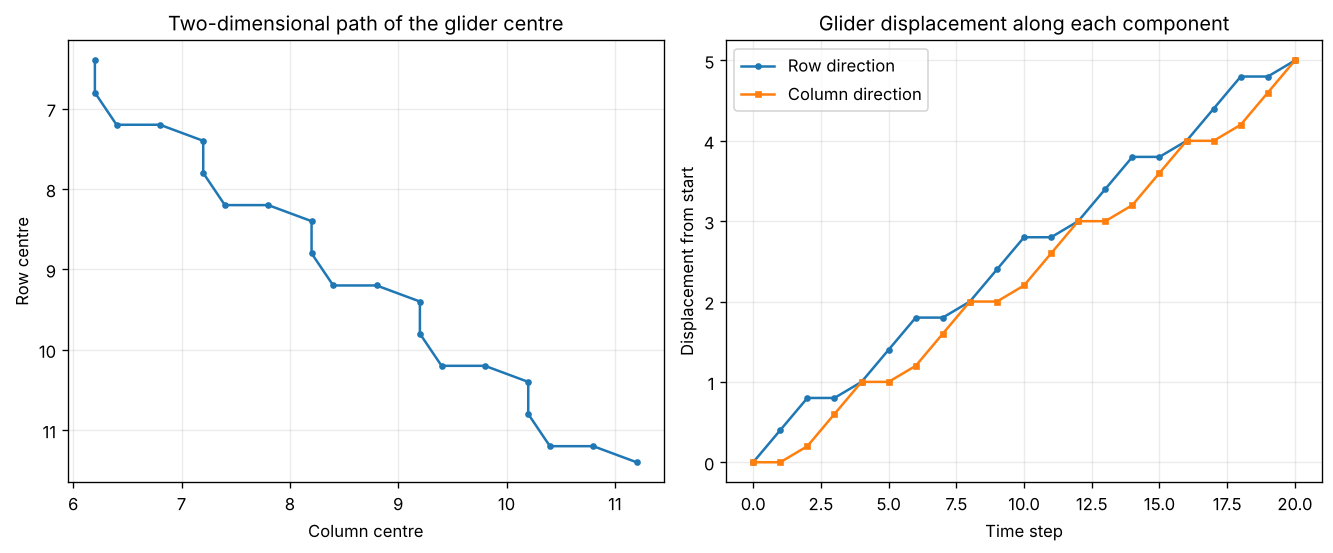

Is the t=4 pattern the t=0 pattern shifted by (1,1)? True
Four-step displacement: [1. 1.]
Mean velocity (cells per step): [0.25 0.25]


In [21]:
def _live_centroid_reference(grid):
    positions = np.argwhere(np.asarray(grid) == 1)
    if len(positions) == 0:
        return (np.nan, np.nan)
    return tuple(positions.mean(axis=0))


glider_initial = place_pattern((40, 40), PATTERNS["Glider"], top_left=(5, 5))
glider_history = _simulate_life_reference(glider_initial, 21)
centroids = np.array([_live_centroid_reference(frame) for frame in glider_history])

fig, (ax_path, ax_displacement) = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

ax_path.plot(centroids[:, 1], centroids[:, 0], "o-", markersize=3)
ax_path.invert_yaxis()
ax_path.set(
    xlabel="Column centre",
    ylabel="Row centre",
    title="Two-dimensional path of the glider centre",
)
ax_path.grid(alpha=0.25)

displacement = centroids - centroids[0]
ax_displacement.plot(displacement[:, 0], "o-", markersize=3, label="Row direction")
ax_displacement.plot(displacement[:, 1], "s-", markersize=3, label="Column direction")
ax_displacement.set(
    xlabel="Time step",
    ylabel="Displacement from start",
    title="Glider displacement along each component",
)
ax_displacement.grid(alpha=0.25)
ax_displacement.legend()
plt.show()

shifted_after_four = np.roll(np.roll(glider_history[0], 1, axis=0), 1, axis=1)
print("Is the t=4 pattern the t=0 pattern shifted by (1,1)?",
      np.array_equal(glider_history[4], shifted_after_four))
print("Four-step displacement:", centroids[4] - centroids[0])
print("Mean velocity (cells per step):", (centroids[4] - centroids[0]) / 4)

### Interpret the glider measurement

1. After four steps, how are the orientation and shape of the pattern related to the initial ones?
2. What is the displacement over four steps?
3. What are the mean velocity components in the row and column directions?
4. Is the population of the glider constant? Does this mean that the individual cells stay fixed?

**My answers:**

> After four steps the shape and orientation of the pattern are exactly the same as at the start. Only its position has changed. The four-step displacement is about one cell diagonally, that is, one unit in the row direction and one unit in the column direction. The mean velocity component in the row direction is 0.25 cells per step and the mean velocity component in the column direction is also 0.25 cells per step. The population of the glider is constant, with 5 live cells at every step. But this does not mean that individual cells stay in place, because some cells die while cells at other positions are born. What stays constant is the population count, not the identity of the cells.

<details>
<summary>Question: Is the glider really the same five cells moving?</summary>

No. The grid cells are at fixed positions. Some cells die while others at different positions are born. The four-step sequence of births and deaths causes the same large-scale shape to re-form one cell diagonally away. What moves is not the individual cells but the pattern.
</details>

## 9. Why is the glider an emergent object?

The microscopic model contains only:

- fixed grid points
- 0/1 states
- the count of eight neighbours
- the B3/S23 update.

At a larger scale, however, we describe the glider with properties such as:

- position
- direction
- period
- velocity
- lifetime
- the ability to collide with other patterns.

These properties are not written into the rule of a single cell. They arise from the organised evolution of many cells. In a similar way in physics, collective or effective objects can form from microscopic constituents.

### Short questions

1. In what ways is it useful to call the glider a "particle"?
2. In what ways is this analogy incomplete?
3. Can we change the velocity of the glider by changing the velocity of a single cell?
4. How can complex collisions arise even though the Game of Life is deterministic?

**My answers:**

> 1. Calling the glider a particle is useful because it moves with a constant velocity, in a constant direction and with a constant shape, which resembles the motion of a real particle. 2. The analogy is incomplete because the glider has no real mass or energy, and no cell physically moves. Only births and deaths take place. 3. No, we cannot change the velocity of a single cell, because cells can only be alive or dead. The concept of velocity is not defined for a single cell, only for the whole pattern. 4. Although the Game of Life is deterministic, when many simple cells change together according to the same rule, complex patterns and collisions that are hard to predict can arise.

## 10. Optional investigation: a one-cell perturbation of a glider

Make a direct connection with Week 3:

1. Take the normal glider grid as `A(0)`.
2. Create `B(0)` by changing a cell near the glider.
3. Advance both systems for 30 to 50 steps.
4. Compute the difference field and the Hamming distance.
5. Does the perturbation destroy the glider, change its direction or create new structures?

Compare two experiments by changing a cell **inside** and **far from** the glider. Use a grid large enough not to reach the periodic boundary.

*[Status note added during review: this optional investigation was not carried out. The code cell below is still empty.]*

In [22]:
# OPTIONAL: carry out the glider perturbation experiment here.
# Add at least one figure and a short markdown interpretation.

## 11. Conclusion and weekly checkpoint

### Main results table

| Structure | Population behaviour | Period | Motion | Emergent property |
|---|---|---:|---|---|
| Block | Constant, 4 | 1 | None | The balance of births and deaths forms a still life |
| Beehive | Constant, 6 | 1 | None | The edge cells keep the neighbour counts in balance |
| Blinker | Constant, 3 | 2 | None | Horizontal and vertical oscillation |
| Toad | Constant, 6 | 2 | None | Oscillation between two shapes |
| Glider | Constant, 5 | 4 | 1 cell diagonally per period | A pattern that moves while keeping its shape |

*[Correction made during review: the toad population was given as "varies between 6 and 8" in the original. The computed population time series shows a constant value of 6.]*

### Exit question

Answer the following question in 7 to 10 sentences:

> Why can the glider in the Game of Life be considered an emergent object? Use the concepts **local rule**, **microscopic cell**, **large-scale pattern**, **period**, **displacement** and **effective velocity** in your answer.

**My answer:**

> The glider can be considered an emergent object because the concept of a glider does not exist inside the local rule. The local rule only looks at the neighbours of a microscopic cell and decides whether that cell will be alive or dead. But when many cells change together according to this simple rule, a large-scale pattern appears. This pattern has a fixed period and repeats itself in the same shape every four steps. During each period the pattern is displaced by one cell diagonally. An effective velocity can be calculated from this displacement, and it is a quarter of a cell per step. No information such as position, direction or velocity is written into the local rule itself. All these properties arise spontaneously from the collective, organised evolution of the cells. The glider is therefore an emergent object that is not directly expected from the microscopic rule but is observed at a larger scale.

### Bring to the meeting

- all six exercise tests passing
- the pre-experiment predictions
- the figure showing the first five steps of the five structures
- the completed classification and main results tables
- the population plot and period measurements
- the glider path, displacement and velocity calculation
- your answers to the short questions
- **two questions** you would like to discuss.

### GitHub submission

File name:

```text
04_game_of_life.ipynb
```

Suggested commit message:

```text
Week 4: Conway's Game of Life
```

Before submitting, run `Restart Kernel and Run All Cells`. Leave the test outputs and figures in the notebook.